## Stations analysis: silver -> gold
- Goal of this notebook: the first half of our Part 1 question:
- What is the USUAL number of riders of each station, by day of the week and by hour,
and which stations are the busiest ones (our "critical" stations)?

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, count, round, to_date, dayofweek, hour, date_format
 
# the silver tables are small (17 MB), so the default memory of Spark is enough here
spark = SparkSession.builder.appName("NYC Subway - Part 1 - stations").getOrCreate()

# folders inside the Docker container (our repo is mounted at /home/jovyan/project)
SILVER = "../data/silver"   # input: the clean tables made by 02_clean.ipynb
GOLD = "../data/gold"       # output: our result tables (Parquet, not on GitHub)
RESULTS = "../results"      # output: small CSV files and figures (on GitHub)


26/10/17 04:39:42 WARN Utils: Your hostname, DESKTOP-JMFFE1L resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/17 04:39:42 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 04:39:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### Read the clean tables and check the join key


In [2]:
station_hour = spark.read.parquet(SILVER + "/station_hour")   # one row = one station, one hour, its riders
complexes = spark.read.parquet(SILVER + "/complexes")         # one row = one station (name, borough)
print("station_hour:", station_hour.count())
print("complexes:", complexes.count())
 
# Before a join we check the key: is every station of station_hour also in complexes?
# left_anti keeps the ids that have NO match in the right table (we expect 0,
# otherwise those stations would silently disappear in the join)
missing = station_hour.select("complex_id").distinct().join(complexes, "complex_id", "left_anti")
print("ridership stations without a name:", missing.count())


station_hour: 3620146
complexes: 445


ridership stations without a name: 0


### Join: add the name and borough of the station, <br> then the calendar columns each ridership row gets the name and the borough of its station


In [3]:
rides = station_hour.join(complexes, "complex_id")
 
# calendar columns, to group by day and hour later (TP part "Datetime Functions")
rides = rides.withColumn("date", to_date(col("transit_timestamp")))           # e.g. 2024-12-12
rides = rides.withColumn("dow", dayofweek(col("transit_timestamp")))          # 1 = Sunday, 2 = Monday ... 7 = Saturday
rides = rides.withColumn("day", date_format(col("transit_timestamp"), "E"))   # Mon, Tue, ...
rides = rides.withColumn("hour", hour(col("transit_timestamp")))              # 0 ... 23
 
# same number of rows as station_hour: the join did not lose or copy any row
print("rows after the join:", rides.count())
rides.show(3)


rows after the join: 3620146
+----------+-------------------+------+------------+---------+-------+----------+---+---+----+
|complex_id|  transit_timestamp|riders|complex_name|  borough|n_stops|      date|dow|day|hour|
+----------+-------------------+------+------------+---------+-------+----------+---+---+----+
|       297|2024-12-12 07:00:00|   292|      215 St|Manhattan|      1|2024-12-12|  5|Thu|   7|
|        43|2024-10-29 16:00:00|   288| Parkside Av| Brooklyn|      1|2024-10-29|  3|Tue|  16|
|        91|2024-12-20 17:00:00|   115|  Alabama Av| Brooklyn|      1|2024-12-20|  6|Fri|  17|
+----------+-------------------+------+------------+---------+-------+----------+---+---+----+
only showing top 3 rows



### How many Mondays, Tuesdays, ... are in our 12 months
- We need these numbers to compute a correct average in the next cell
distinct() keeps each date only once, then we count the dates of each day of the week

In [4]:
days = rides.select("date", "dow").distinct().groupBy("dow").agg(count("*").alias("n_days"))
days.orderBy("dow").show()

+---+------+
|dow|n_days|
+---+------+
|  1|    52|
|  2|    53|
|  3|    52|
|  4|    52|
|  5|    52|
|  6|    52|
|  7|    52|
+---+------+



## GOLD 1: usual riders per station, day of the week and hour

- IMPORTANT: the MTA writes NO row when a station has 0 riders in an hour.
- So avg() would be wrong here: it only averages the rows that exist and forgets the zeros.
- Example: a small station has riders on 40 Mondays at 3 am and nobody on the 13 other Mondays.
   avg() divides by 40 (too high), the correct way divides by 53 (all the Mondays of the year).
- So: usual riders = total riders of that (station, day, hour) / number of such days


In [ ]:

profile = rides.groupBy("complex_id", "complex_name", "borough", "dow", "day", "hour").agg(sum("riders").alias("total_riders"))
profile = profile.join(days, "dow")   # adds n_days: 53 for Monday, 52 for the other days
profile = profile.withColumn("usual_riders", round(col("total_riders") / col("n_days"), 1))
 
# saved in gold: we will reuse it in Part 2 ("how busy is this station normally at this hour?")
profile.write.mode("overwrite").parquet(GOLD + "/station_profile")
station_profile = spark.read.parquet(GOLD + "/station_profile")
print("station_profile:", station_profile.count())
 
# the 5 busiest (station, day, hour) of the year
station_profile.orderBy(col("usual_riders").desc()).show(5, truncate=False)


station_profile: 71232
 +---+----------+-------------------+---------+---+----+------------+------+------------+
 |dow|complex_id|complex_name       |borough  |day|hour|total_riders|n_days|usual_riders|
 +---+----------+-------------------+---------+---+----+------------+------+------------+
 |3  |610       |Grand Central-42 St|Manhattan|Tue|17  |997115      |52    |19175.3     |
 |4  |610       |Grand Central-42 St|Manhattan|Wed|17  |974833      |52    |18746.8     |
 |5  |610       |Grand Central-42 St|Manhattan|Thu|17  |896451      |52    |17239.4     |
 |4  |611       |Times Sq-42 St     |Manhattan|Wed|17  |828610      |52    |15934.8     |
 |3  |611       |Times Sq-42 St     |Manhattan|Tue|17  |810265      |52    |15582.0     |
 +---+----------+-------------------+---------+---+----+------------+------+------------+
 only showing top 5 rows


## GOLD 2: Busiest stations = average riders per day over the 12 months
- Our definition of a "critical" station: the more people use it, the more people are affected when something goes wrong there

In [6]:
n_days = rides.select("date").distinct().count()   # number of days in our window
print("days:", n_days)
 
ranking = rides.groupBy("complex_id", "complex_name", "borough").agg(sum("riders").alias("total_riders"))
ranking = ranking.withColumn("riders_per_day", round(col("total_riders") / n_days))
ranking = ranking.orderBy(col("riders_per_day").desc())
 
ranking.write.mode("overwrite").parquet(GOLD + "/station_ranking")
# small CSV for the report; coalesce(1) = one single file (as in the TP)
ranking.coalesce(1).write.mode("overwrite").option("header", True).csv(RESULTS + "/station_ranking")
ranking.show(10, truncate=False)


days: 365


+----------+------------------------+---------+------------+--------------+
|complex_id|complex_name            |borough  |total_riders|riders_per_day|
+----------+------------------------+---------+------------+--------------+
|611       |Times Sq-42 St          |Manhattan|47368725    |129777.0      |
|610       |Grand Central-42 St     |Manhattan|35083558    |96119.0       |
|607       |34 St-Herald Sq         |Manhattan|25849995    |70822.0       |
|602       |14 St-Union Sq          |Manhattan|23798419    |65201.0       |
|628       |Fulton St               |Manhattan|19940111    |54630.0       |
|164       |34 St-Penn Station      |Manhattan|19298760    |52873.0       |
|318       |34 St-Penn Station      |Manhattan|17646637    |48347.0       |
|614       |59 St-Columbus Circle   |Manhattan|17189584    |47095.0       |
|447       |Flushing-Main St        |Queens   |15010250    |41124.0       |
|616       |Jackson Hts-Roosevelt Av|Queens   |14792225    |40527.0       |
+----------+

In [7]:
## 7. The whole network: usual riders per day of the week and hour
# we add up the usual riders of all the stations: one row per (day, hour) = 7 x 24 = 168 rows
network = station_profile.groupBy("dow", "day", "hour").agg(round(sum("usual_riders")).alias("usual_riders"))
network = network.orderBy("dow", "hour")
network.coalesce(1).write.mode("overwrite").option("header", True).csv(RESULTS + "/network_profile")
 
# Monday hour by hour: we should see the two rush hours (around 8 am and 5 pm)
network.where("dow = 2").show(24)


+---+---+----+------------+
|dow|day|hour|usual_riders|
+---+---+----+------------+
|  2|Mon|   0|     19417.0|
|  2|Mon|   1|      8272.0|
|  2|Mon|   2|      5481.0|
|  2|Mon|   3|      6524.0|
|  2|Mon|   4|     18123.0|
|  2|Mon|   5|     62344.0|
|  2|Mon|   6|    138386.0|
|  2|Mon|   7|    267618.0|
|  2|Mon|   8|    327578.0|
|  2|Mon|   9|    210981.0|
|  2|Mon|  10|    149960.0|
|  2|Mon|  11|    142011.0|
|  2|Mon|  12|    151538.0|
|  2|Mon|  13|    170214.0|
|  2|Mon|  14|    206844.0|
|  2|Mon|  15|    262082.0|
|  2|Mon|  16|    300462.0|
|  2|Mon|  17|    358362.0|
|  2|Mon|  18|    263693.0|
|  2|Mon|  19|    167663.0|
|  2|Mon|  20|    122836.0|
|  2|Mon|  21|     96144.0|
|  2|Mon|  22|     71969.0|
|  2|Mon|  23|     43314.0|
+---+---+----+------------+



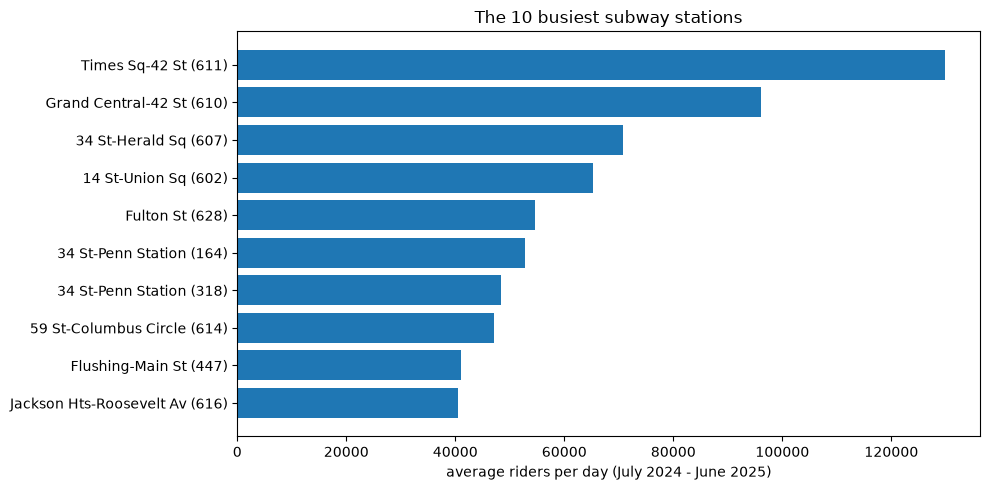

In [8]:
## Figure 1: the 10 busiest stations
# toPandas() brings a SMALL Spark table into normal Python, so matplotlib can draw it
# (never do it with a big table: it must fit in the memory of one computer)
import os
import matplotlib.pyplot as plt
os.makedirs(RESULTS + "/figures", exist_ok=True)   # creates results/figures if it does not exist
 
top10 = ranking.limit(10).toPandas()
# two different stations are both called "34 St-Penn Station", so we add the id to the name
top10["label"] = top10["complex_name"] + " (" + top10["complex_id"].astype(str) + ")"
 
plt.figure(figsize=(10, 5))
plt.barh(top10["label"], top10["riders_per_day"])   # horizontal bars: long names stay readable
plt.gca().invert_yaxis()                             # the busiest station on top
plt.xlabel("average riders per day (July 2024 - June 2025)")
plt.title("The 10 busiest subway stations")
plt.tight_layout()
plt.savefig(RESULTS + "/figures/top10_stations.png", dpi=150)   # the picture for the report
plt.show()


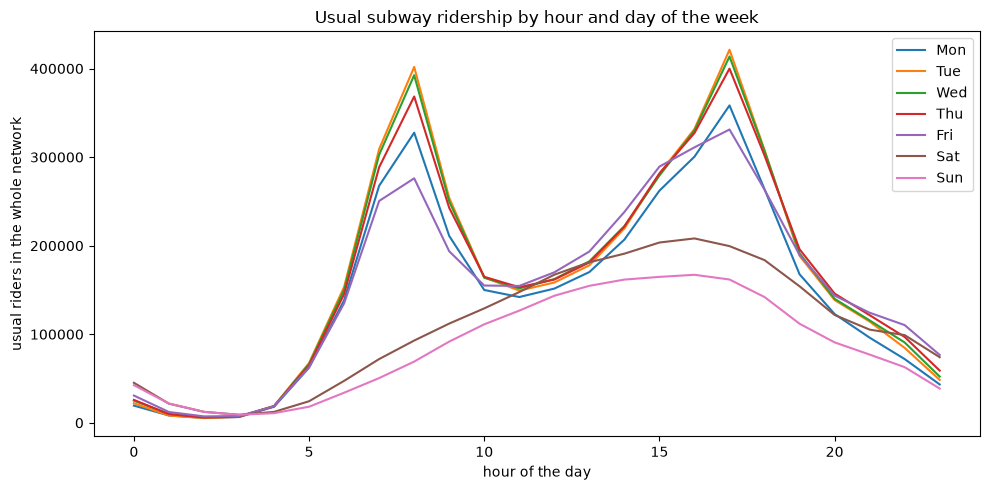

In [9]:
## Figure 2: usual ridership of the whole network by hour, one line per day
net = network.toPandas()   # 168 rows only, so toPandas() is fine
 
plt.figure(figsize=(10, 5))
for d in ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]:
    one_day = net[net["day"] == d]   # the 24 rows of that day
    plt.plot(one_day["hour"], one_day["usual_riders"], label=d)
plt.xlabel("hour of the day")
plt.ylabel("usual riders in the whole network")
plt.title("Usual subway ridership by hour and day of the week")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS + "/figures/network_profile.png", dpi=150)
plt.show()
